# Comptage de mots avec Apache Spark (PySpark)

**Cours :** Fondements et Application de Big Data (13/10/2026)
**Thème :** Apache Spark, depuis PySpark

## Consigne

| # | À faire |
|---|---------|
| 1 | Reprendre le même exemple : le comptage d'occurrences de mots dans un fichier |
| 2 | L'implémenter avec Apache Spark, depuis PySpark |
| 3 | Le tester et le comparer aux méthodes du TP précédent, sur les mêmes fichiers |

**Génération des fichiers** (inchangée) :
- générer un fichier de **N lignes**, chaque ligne contenant **un mot** (avec répétition) ;
- générer un fichier plus gros de **m × N lignes** en dupliquant les N lignes **m fois** ;
- faire varier **m** pour obtenir des fichiers de plus en plus gros (attention au temps d'exécution).

**Rendu :** ce notebook, avec le problème, les explications, le code, les tests, les comparaisons et la conclusion.

## Le problème

On dispose d'un fichier texte et on veut savoir combien de fois chaque mot y apparaît. Le TP précédent
(`comptage_mots.ipynb`) l'a résolu de trois façons : Python simple (V1), pseudo-MapReduce en Python (V2)
et Hadoop MapReduce sur un cluster HDFS + YARN (V3). Hadoop payait environ 30 s à chaque lancement,
quelle que soit la taille du fichier. On regarde ici ce que change **Spark**, avec ses deux API :
les **RDD** (V4) et les **DataFrames** (V5).

## Plan

1. Environnement et installation
2. Principe de Spark
3. Fichiers de test
4. Version 4 : Spark avec les RDD
5. Version 5 : Spark avec les DataFrames
6. Tests de justesse
7. Comparaison des performances
8. Analyse et conclusion

## 1. Environnement et installation

PySpark s'installe avec `pip` : le paquet contient Spark lui-même (les fichiers `.jar`), il n'y a pas de
cluster à monter. Il lui faut seulement une machine virtuelle Java.

```bash
pip install "pyspark>=3.5,<3.6" jupyter pandas matplotlib
```

- **Version :** Spark 3.5 accepte Java 8, 11 ou 17. Spark 4 exige Java 17 : on reste donc en 3.5,
  qui fonctionne avec le Java 8 déjà installé sur la machine.
- **Mode local :** avec `master("local[*]")`, le *driver* et les *executors* tournent dans une seule JVM,
  avec un fil d'exécution par cœur logique. Il n'y a ni HDFS ni YARN : Spark lit directement les fichiers
  du disque.
- **Sous Windows :** Spark lance par défaut la commande `python3` pour ses processus Python, qui n'existe
  pas toujours. On lui indique l'interpréteur courant avec `PYSPARK_PYTHON`. L'avertissement
  « Did not find winutils.exe » au démarrage est sans conséquence ici : on ne fait que lire des fichiers.

La partie Hadoop de la comparaison (partie 7) réutilise le cluster Docker du TP précédent. Sans Docker,
elle est sautée.

In [1]:
import os, sys, platform, subprocess, time, random, gc, re
from collections import Counter
from operator import add
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable

import pyspark
from pyspark.sql import SparkSession, functions as F

def sh(cmd, check=True, **kw):
    # Lance une commande shell et renvoie sa sortie standard (texte).
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True,
                       encoding="utf-8", errors="replace", **kw)
    if check and r.returncode != 0:
        raise RuntimeError(f"Échec ({r.returncode}) : {cmd}\n{r.stdout[-2000:]}\n{r.stderr[-2000:]}")
    return r

def lignes_resultat(sortie):
    # Garde les lignes « mot : nombre » (sous Windows, l'arrêt de Spark écrit aussi sur la sortie standard).
    return "\n".join(l for l in sortie.splitlines() if re.fullmatch(r"\S+ : \d+", l))

print("Python     :", sys.version.split()[0])
print("Système    :", platform.platform())
print("Processeur :", platform.processor() or "?", "-", os.cpu_count(), "cœurs logiques")
print("PySpark    :", pyspark.__version__)
r = sh("java -version", check=False)
print("Java       :", (r.stderr or r.stdout).splitlines()[0] if r.returncode == 0 else "NON TROUVÉ")
r = sh("docker version --format {{.Server.Version}}", check=False)
print("Docker     :", r.stdout.strip() or "NON DISPONIBLE (la partie Hadoop sera sautée)")
DOCKER_OK = r.returncode == 0

Python     : 3.11.9
Système    : Windows-10-10.0.26300-SP0
Processeur : Intel64 Family 6 Model 154 Stepping 4, GenuineIntel - 12 cœurs logiques
PySpark    : 3.5.9


Java       : java version "1.8.0_471"


Docker     : 28.4.0


Démarrage de Spark. La `SparkSession` est le point d'entrée des DataFrames, son `SparkContext` celui
des RDD. C'est ici que la JVM est lancée : on mesure ce temps, il n'est payé qu'une fois par programme.
Tant que la session vit, l'interface web de Spark (http://localhost:4040) montre les jobs, les stages et les tâches.

In [2]:
def creer_session(master="local[*]"):
    # Crée une session Spark locale ; master = "local[k]" pour k fils d'exécution.
    session = (SparkSession.builder.master(master).appName("tp-comptage-spark")
               .config("spark.ui.showConsoleProgress", "false")
               .getOrCreate())
    session.sparkContext.setLogLevel("ERROR")
    return session


t0 = time.perf_counter()
spark = creer_session()
sc = spark.sparkContext
t_session = time.perf_counter() - t0

print(f"Session Spark prête en {t_session:.1f} s")
print("Spark       :", spark.version)
print("Master      :", sc.master)
print("Parallélisme:", sc.defaultParallelism, "tâches simultanées")

Session Spark prête en 10.7 s
Spark       : 3.5.9
Master      : local[*]
Parallélisme: 12 tâches simultanées


## 2. Principe de Spark

Spark est, comme Hadoop MapReduce, un moteur de calcul distribué. Il s'en distingue sur trois points.

- **Un programme, pas un job par étape.** Un programme *driver* décrit le calcul comme une suite
  d'opérations sur des collections distribuées. Spark en tire un graphe (DAG), le découpe en *stages*
  et envoie des *tâches* aux *executors*. Les JVM restent en vie d'un calcul à l'autre : on ne paie pas
  leur démarrage à chaque job, contrairement à Hadoop.
- **Les opérations s'enchaînent en mémoire** à l'intérieur d'un stage, sans fichier intermédiaire. Seul
  le shuffle passe par des fichiers locaux. Hadoop MapReduce écrit aussi sur disque entre le map et le
  reduce, et dans HDFS entre deux jobs.
- **L'évaluation est paresseuse.** Une *transformation* (`map`, `flatMap`, `filter`, `reduceByKey`...)
  ne calcule rien : elle ajoute une étape au graphe. Seule une *action* (`collect`, `count`,
  `saveAsTextFile`...) déclenche l'exécution.

Deux API permettent d'écrire le même calcul :

| | RDD | DataFrame |
|---|---|---|
| Donnée | collection distribuée d'objets quelconques | table distribuée, avec des colonnes typées |
| On écrit | des fonctions Python (`lambda`) | des expressions sur les colonnes (`split`, `groupBy`...) |
| Qui exécute | des processus Python lancés par la JVM | la JVM seule, après optimisation (Catalyst) |
| Niveau | bas : proche de MapReduce | haut : proche de SQL |

Le comptage de mots s'y écrit avec les mêmes étapes que dans MapReduce :

```
           MAP                           SHUFFLE                        REDUCE
textFile -> flatMap(split) -> map((mot, 1))  ------>  reduceByKey(add)  ------>  collect()
            \_____________ stage 1 _____________/      \__________ stage 2 __________/
```

`flatMap` et `map` travaillent partition par partition, sans échange de données. `reduceByKey` a besoin de
réunir toutes les paires d'un même mot : c'est le **shuffle**, qui sépare les deux stages. Comme le
*combiner* de Hadoop, `reduceByKey` fait déjà les sommes à l'intérieur de chaque partition avant le shuffle.

## 3. Fichiers de test

On reprend exactement le générateur du TP précédent, avec la même graine : les fichiers sont identiques,
donc les résultats et les temps sont comparables. Le fichier de base contient **N = 100 000 lignes**
(un mot par ligne, tiré dans un vocabulaire de 15 mots avec des poids de type Zipf). Les fichiers plus
gros sont **m copies** du fichier de base : chaque compte y vaut m fois celui du fichier de base, ce qui
sert de test.

In [3]:
# Paramètres de l'expérience (identiques au TP précédent)
N = 100_000                      # nombre de lignes du fichier de base
M_VALUES = [1, 10, 50, 100, 200]  # facteurs de duplication
SEED = 42

VOCABULAIRE = ["chat", "chien", "arbre", "fleur", "maison", "soleil", "montagne", "livre",
               "ciel", "mer", "lune", "route", "oiseau", "jardin", "voiture"]

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

In [4]:
def generer_fichier_base(chemin, n, vocabulaire, seed=SEED):
    # Écrit n lignes, un mot par ligne, tiré avec remise (poids 1/rang : loi de type Zipf).
    rng = random.Random(seed)
    poids = [1 / (rang + 1) for rang in range(len(vocabulaire))]
    mots = rng.choices(vocabulaire, weights=poids, k=n)
    with open(chemin, "w", encoding="utf-8", newline="\n") as f:
        f.write("\n".join(mots) + "\n")
    return chemin


def dupliquer_fichier(source, destination, m):
    # Écrit m copies successives des lignes de `source` dans `destination` (m x N lignes).
    contenu = Path(source).read_bytes()
    with open(destination, "wb") as f:
        for _ in range(m):
            f.write(contenu)
    return destination


def compter_lignes(chemin):
    with open(chemin, "rb") as f:
        return sum(buf.count(b"\n") for buf in iter(lambda: f.read(1 << 20), b""))


fichier_base = generer_fichier_base(DATA_DIR / "mots.txt", N, VOCABULAIRE)

FICHIERS = {}
for m in M_VALUES:
    FICHIERS[m] = dupliquer_fichier(fichier_base, DATA_DIR / f"mots_m{m}.txt", m)

inventaire = pd.DataFrame([
    {"m": m, "fichier": p.as_posix(), "lignes": compter_lignes(p),
     "taille (Mo)": round(p.stat().st_size / 1e6, 2)}
    for m, p in FICHIERS.items()
])
inventaire

,m,fichier,lignes,taille (Mo)
0,1,data/mots_m1.txt,100000,0.59
1,10,data/mots_m10.txt,1000000,5.91
2,50,data/mots_m50.txt,5000000,29.54
3,100,data/mots_m100.txt,10000000,59.07
4,200,data/mots_m200.txt,20000000,118.14


## 4. Version 4 : Spark avec les RDD

Un **RDD** (*Resilient Distributed Dataset*) est une collection découpée en **partitions**, que Spark
traite en parallèle. Il est immuable : chaque transformation en produit un nouveau.

### 4.1 Les étapes sur un petit exemple

`parallelize` transforme une liste Python en RDD (ici en 2 partitions). On affiche le contenu après
chaque transformation avec l'action `collect()`.

In [5]:
lignes = sc.parallelize(["chat", "chien", "chat", "arbre", "chat"], 2)
mots = lignes.flatMap(lambda ligne: ligne.split())
paires = mots.map(lambda mot: (mot, 1))
comptes = paires.reduceByKey(add)

print("partitions  :", lignes.glom().collect())
print("flatMap     :", mots.collect())
print("map         :", paires.collect())
print("reduceByKey :", comptes.collect())

partitions  : [['chat', 'chien'], ['chat', 'arbre', 'chat']]


flatMap     : ['chat', 'chien', 'chat', 'arbre', 'chat']


map         : [('chat', 1), ('chien', 1), ('chat', 1), ('arbre', 1), ('chat', 1)]


reduceByKey : [('arbre', 1), ('chat', 3), ('chien', 1)]


`flatMap` applique une fonction qui renvoie une liste par ligne (les mots de la ligne) et met toutes ces
listes bout à bout. Avec `map`, on obtiendrait une liste de listes. `reduceByKey(add)` regroupe les
paires par clé et combine leurs valeurs deux à deux avec `add`.

### 4.2 Le programme

Même organisation que `wordcount.py` et `mapreduce_wordcount.py` : une fonction réutilisable, et un
script qu'on peut lancer en ligne de commande. Le fichier contient aussi la version DataFrame, expliquée
dans la partie 5.

In [6]:
%%writefile spark_wordcount.py
import os
import sys
from operator import add

from pyspark.sql import SparkSession, functions as F


def compter_spark_rdd(sc, fichier, partitions=None):
    comptes = (sc.textFile(str(fichier), partitions)
                 .flatMap(lambda ligne: ligne.split())
                 .map(lambda mot: (mot, 1))
                 .reduceByKey(add))
    return dict(comptes.collect())


def compter_spark_df(spark, fichier):
    mots = (spark.read.text(str(fichier))
                 .select(F.explode(F.split(F.col("value"), r"\s+")).alias("mot"))
                 .where(F.col("mot") != ""))
    comptes = mots.groupBy("mot").count()
    return {ligne["mot"]: ligne["count"] for ligne in comptes.collect()}


if __name__ == "__main__":
    fichier = sys.argv[1] if len(sys.argv) > 1 else "mots.txt"
    api = sys.argv[2] if len(sys.argv) > 2 else "rdd"
    sys.stdout.reconfigure(encoding="utf-8")    # même redirigée, la sortie reste en UTF-8 (accents)
    os.environ.setdefault("PYSPARK_PYTHON", sys.executable)
    spark = SparkSession.builder.master("local[*]").appName("wordcount").getOrCreate()
    spark.sparkContext.setLogLevel("ERROR")
    if api == "df":
        resultats = compter_spark_df(spark, fichier)
    else:
        resultats = compter_spark_rdd(spark.sparkContext, fichier)
    for mot, nb in sorted(resultats.items(), key=lambda x: x[1], reverse=True):
        print(f"{mot} : {nb}")
    spark.stop()

Overwriting spark_wordcount.py


Exécution du script en ligne de commande, chronométrée de bout en bout comme dans le TP précédent.
Ce temps inclut le démarrage de Python **et de la JVM de Spark** : c'est l'équivalent du coût fixe
de `hadoop jar`.

In [7]:
t0 = time.perf_counter()
r = sh(f'"{sys.executable}" spark_wordcount.py {fichier_base.as_posix()}')
t_cli_rdd = time.perf_counter() - t0
print(lignes_resultat(r.stdout))
print(f"Temps total (démarrage de Python et de Spark compris) : {t_cli_rdd:.1f} s")

chat : 30137
chien : 15038
arbre : 10000
fleur : 7455
maison : 6103
soleil : 5003
montagne : 4375
livre : 3837
ciel : 3353
mer : 2968
lune : 2641
route : 2560
oiseau : 2308
jardin : 2197
voiture : 2025
Temps total (démarrage de Python et de Spark compris) : 16.8 s


### 4.3 Évaluation paresseuse et graphe d'exécution

Dans le notebook, la session Spark est déjà démarrée. On construit le RDD sur le fichier d'un million de
lignes, puis on déclenche le calcul : la construction ne prend qu'une fraction de seconde, presque tout le
temps est dans l'action.

In [8]:
from spark_wordcount import compter_spark_rdd, compter_spark_df

t0 = time.perf_counter()
rdd = (sc.textFile(FICHIERS[10].as_posix())
         .flatMap(lambda ligne: ligne.split())
         .map(lambda mot: (mot, 1))
         .reduceByKey(add))
t_transformations = time.perf_counter() - t0

t0 = time.perf_counter()
resultat = rdd.collect()
t_action = time.perf_counter() - t0

print(f"Transformations (textFile, flatMap, map, reduceByKey) : {t_transformations:.3f} s")
print(f"Action collect()                                      : {t_action:.3f} s")
print("Partitions du fichier :", sc.textFile(FICHIERS[10].as_posix()).getNumPartitions())
print(sorted(resultat, key=lambda x: -x[1])[:5])

Transformations (textFile, flatMap, map, reduceByKey) : 0.338 s
Action collect()                                      : 6.443 s
Partitions du fichier : 2
[('chat', 301370), ('chien', 150380), ('arbre', 100000), ('fleur', 74550), ('maison', 61030)]


`toDebugString()` affiche le lignage du RDD, à lire de bas en haut. Le décalage marque la frontière
entre les deux stages : en dessous, la lecture et le map ; au-dessus, ce qui suit le shuffle.

In [9]:
for ligne in rdd.toDebugString().decode().splitlines():
    print(re.sub(r"(\[\d+\] at \w+) at .*", r"\1", ligne))   # on masque le chemin du fichier source

(2) PythonRDD[15] at collect
 |  MapPartitionsRDD[14] at mapPartitions
 |  ShuffledRDD[13] at partitionBy
 +-(2) PairwiseRDD[12] at reduceByKey
    |  PythonRDD[11] at reduceByKey
    |  data/mots_m10.txt MapPartitionsRDD[10] at textFile
    |  data/mots_m10.txt HadoopRDD[9] at textFile


## 5. Version 5 : Spark avec les DataFrames

Un **DataFrame** est une table distribuée. `spark.read.text` renvoie une table à une colonne `value`
(une ligne du fichier par ligne de la table). On ne lui passe plus des fonctions Python mais des
**expressions** :

- `split(value, "\s+")` découpe la ligne en tableau de mots ;
- `explode` produit une ligne par élément du tableau (l'équivalent de `flatMap`) ;
- `where(mot != "")` écarte les chaînes vides laissées par `split` quand une ligne commence par un blanc ;
- `groupBy("mot").count()` regroupe et compte (l'équivalent de `map` + `reduceByKey`).

Le code de `compter_spark_df` est dans `spark_wordcount.py` (partie 4.2). On le déroule ici pas à pas.

In [10]:
df_lignes = spark.read.text(fichier_base.as_posix())
df_mots = (df_lignes.select(F.explode(F.split(F.col("value"), r"\s+")).alias("mot"))
                    .where(F.col("mot") != ""))
df_comptes = df_mots.groupBy("mot").count()

df_lignes.printSchema()
df_comptes.orderBy(F.desc("count")).show()

root
 |-- value: string (nullable = true)



+--------+-----+
|     mot|count|
+--------+-----+
|    chat|30137|
|   chien|15038|
|   arbre|10000|
|   fleur| 7455|
|  maison| 6103|
|  soleil| 5003|
|montagne| 4375|
|   livre| 3837|
|    ciel| 3353|
|     mer| 2968|
|    lune| 2641|
|   route| 2560|
|  oiseau| 2308|
|  jardin| 2197|
| voiture| 2025|
+--------+-----+



La même requête peut s'écrire en SQL, en enregistrant la table sous un nom. Spark en tire le même plan
d'exécution.

In [11]:
df_lignes.createOrReplaceTempView("lignes")
spark.sql("""
    SELECT mot, COUNT(*) AS nb
    FROM (SELECT explode(split(value, '\\\\s+')) AS mot FROM lignes)
    WHERE mot != ''
    GROUP BY mot
    ORDER BY nb DESC
    LIMIT 5
""").show()

+------+-----+
|   mot|   nb|
+------+-----+
|  chat|30137|
| chien|15038|
| arbre|10000|
| fleur| 7455|
|maison| 6103|
+------+-----+



`explain()` affiche le **plan physique** choisi par l'optimiseur, à lire de bas en haut. On y retrouve
les trois temps de MapReduce : un premier `HashAggregate` (sommes partielles dans chaque partition,
le rôle du *combiner*), un `Exchange hashpartitioning` (le shuffle), puis le `HashAggregate` final.

In [12]:
plan = df_comptes._jdf.queryExecution().simpleString()
plan = plan[plan.index("== Physical Plan =="):]
print(re.sub(r"\[file:/[^\]]*\]", "[data/mots.txt]", plan))   # on masque le chemin absolu du fichier

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[mot#3], functions=[count(1)])
   +- Exchange hashpartitioning(mot#3, 200), ENSURE_REQUIREMENTS, [plan_id=155]
      +- HashAggregate(keys=[mot#3], functions=[partial_count(1)])
         +- Filter NOT (mot#3 = )
            +- Generate explode(split(value#0, \s+, -1)), false, [mot#3]
               +- FileScan text [value#0] Batched: false, DataFilters: [], Format: Text, Location: InMemoryFileIndex(1 paths)[data/mots.txt], PartitionFilters: [], PushedFilters: [], ReadSchema: struct<value:string>




In [13]:
t0 = time.perf_counter()
r = sh(f'"{sys.executable}" spark_wordcount.py {fichier_base.as_posix()} df')
t_cli_df = time.perf_counter() - t0
print(lignes_resultat(r.stdout))
print(f"Temps total (démarrage de Python et de Spark compris) : {t_cli_df:.1f} s")

chat : 30137
chien : 15038
arbre : 10000
fleur : 7455
maison : 6103
soleil : 5003
montagne : 4375
livre : 3837
ciel : 3353
mer : 2968
lune : 2641
route : 2560
oiseau : 2308
jardin : 2197
voiture : 2025
Temps total (démarrage de Python et de Spark compris) : 19.0 s


## 6. Tests de justesse

Avant de comparer les temps, on vérifie que les deux versions Spark calculent **la même chose que les
versions du TP précédent, et le bon résultat** :

1. **Tests unitaires** sur de petits fichiers dont on connaît le résultat, cas limites compris
   (fichier vide, lignes vides, espaces en trop, plusieurs mots par ligne, accents) ;
2. **Référence indépendante** : comparaison avec `collections.Counter` de la bibliothèque standard ;
3. **Propriété de la duplication** : un fichier formé de m copies doit donner exactement
   m × les comptes du fichier de base ;
4. **Toutes les méthodes sont d'accord** : V1, V2, Hadoop, Spark RDD et Spark DataFrame donnent le même
   dictionnaire à chaque taille (vérifié dans la partie 7).

In [14]:
from wordcount import compter_occurrences
from mapreduce_wordcount import compter_mapreduce

TESTS_DIR = DATA_DIR / "tests"
TESTS_DIR.mkdir(exist_ok=True)

CAS = {
    "simple":        ("chat\nchien\nchat\n",                {"chat": 2, "chien": 1}),
    "vide":          ("",                                   {}),
    "lignes_vides":  ("\n\nchat\n\n\nchat\n",               {"chat": 2}),
    "espaces":       ("  chat  \n\tchien\t\nchat",          {"chat": 2, "chien": 1}),
    "plusieurs":     ("chat chien\nchien chien oiseau\n",   {"chat": 1, "chien": 3, "oiseau": 1}),
    "accents":       ("été\nÉté\nété\n",                    {"été": 2, "Été": 1}),
}

for nom, (contenu, attendu) in CAS.items():
    chemin = TESTS_DIR / f"{nom}.txt"
    chemin.write_text(contenu, encoding="utf-8")
    assert compter_occurrences(chemin) == attendu, f"V1 échoue sur {nom}"
    assert compter_mapreduce(chemin) == attendu, f"V2 échoue sur {nom}"
    assert compter_spark_rdd(sc, chemin) == attendu, f"Spark RDD échoue sur {nom}"
    assert compter_spark_df(spark, chemin) == attendu, f"Spark DataFrame échoue sur {nom}"
    print(f"OK  {nom:<13} -> {attendu}")

OK  simple        -> {'chat': 2, 'chien': 1}


OK  vide          -> {}


OK  lignes_vides  -> {'chat': 2}


OK  espaces       -> {'chat': 2, 'chien': 1}


OK  plusieurs     -> {'chat': 1, 'chien': 3, 'oiseau': 1}


OK  accents       -> {'été': 2, 'Été': 1}


Remarque : comme dans le TP précédent, le comptage est sensible à la casse (`été` ≠ `Été`) et découpe
sur les blancs. La version RDD utilise le `split()` de Python. La version DataFrame utilise l'expression
régulière Java `\s+`, qui ne reconnaît que les blancs ASCII (espace, tabulation, retour à la ligne) :
les deux coïncident sur nos fichiers, mais pourraient différer sur un texte contenant des espaces
insécables.

In [15]:
# Référence indépendante + propriété de duplication
with open(fichier_base, encoding="utf-8") as f:
    reference_base = Counter(f.read().split())

assert sum(reference_base.values()) == N
assert compter_spark_rdd(sc, fichier_base) == reference_base
assert compter_spark_df(spark, fichier_base) == reference_base
print("Fichier de base : Spark RDD = Spark DataFrame = Counter  ->", dict(reference_base.most_common(5)), "...")

for m in [m for m in M_VALUES if m <= 10]:   # les gros fichiers sont vérifiés en partie 7
    attendu = {mot: m * nb for mot, nb in reference_base.items()}
    assert compter_spark_rdd(sc, FICHIERS[m]) == attendu
    assert compter_spark_df(spark, FICHIERS[m]) == attendu
    print(f"m = {m:>3} : comptes = {m} x comptes de base  OK")

Fichier de base : Spark RDD = Spark DataFrame = Counter  -> {'chat': 30137, 'chien': 15038, 'arbre': 10000, 'fleur': 7455, 'maison': 6103} ...


m =   1 : comptes = 1 x comptes de base  OK


m =  10 : comptes = 10 x comptes de base  OK


**Preuve que les tests détectent une erreur.** On injecte une faute réaliste : oublier le découpage en
mots et compter les lignes entières (`map` au lieu de `flatMap(split)`). Sur nos fichiers générés, où
chaque ligne contient exactement un mot, cette version fausse donne le **bon** résultat : la comparaison
avec `Counter` ne la voit pas. Ce sont les cas limites (plusieurs mots par ligne, espaces en trop) qui
la détectent.

In [16]:
def compter_spark_rdd_faux(sc, fichier):
    # Faute volontaire : la ligne entière sert de clé, sans découpage en mots.
    return dict(sc.textFile(str(fichier)).map(lambda ligne: (ligne, 1)).reduceByKey(add).collect())

assert compter_spark_rdd_faux(sc, fichier_base) == reference_base
print("Fichier de base : la version fausse passe (une ligne = un mot)")

for nom in ("plusieurs", "espaces"):
    resultat_faux = compter_spark_rdd_faux(sc, TESTS_DIR / f"{nom}.txt")
    assert resultat_faux != CAS[nom][1]
    print(f"Faute détectée sur « {nom} » :", resultat_faux, "!=", CAS[nom][1])

Fichier de base : la version fausse passe (une ligne = un mot)


Faute détectée sur « plusieurs » : {'chien chien oiseau': 1, 'chat chien': 1} != {'chat': 1, 'chien': 3, 'oiseau': 1}


Faute détectée sur « espaces » : {'\tchien\t': 1, '  chat  ': 1, 'chat': 1} != {'chat': 2, 'chien': 1}


## 7. Comparaison des performances

### 7.1 Les coûts fixes de Spark

Avant de mesurer le comptage, on mesure ce que coûte un job Spark **qui ne fait presque rien** :

- un job DataFrame minimal, exécuté entièrement dans la JVM ;
- un job RDD minimal sur 1 partition : la JVM doit lancer **un processus Python** pour exécuter la
  fonction Python de la tâche ;
- le même sur autant de partitions que de cœurs, donc autant de processus Python.

In [17]:
def duree(action):
    t0 = time.perf_counter()
    action()
    return time.perf_counter() - t0


P = sc.defaultParallelism
t_df_min = min(duree(lambda: spark.range(1000).count()) for _ in range(3))
t_rdd_min_1 = min(duree(lambda: sc.parallelize([0], 1).count()) for _ in range(3))
t_rdd_min_p = min(duree(lambda: sc.parallelize(range(P), P).count()) for _ in range(2))

couts = pd.DataFrame([
    {"coût fixe": "Démarrage de la session Spark (JVM), une fois par programme", "temps (s)": t_session},
    {"coût fixe": "Script complet sur 100 000 lignes, API RDD (python spark_wordcount.py)", "temps (s)": t_cli_rdd},
    {"coût fixe": "Script complet sur 100 000 lignes, API DataFrame", "temps (s)": t_cli_df},
    {"coût fixe": "Job DataFrame minimal, session déjà démarrée", "temps (s)": t_df_min},
    {"coût fixe": "Job RDD minimal, 1 partition (1 processus Python)", "temps (s)": t_rdd_min_1},
    {"coût fixe": f"Job RDD minimal, {P} partitions ({P} processus Python)", "temps (s)": t_rdd_min_p},
]).set_index("coût fixe")
couts.round(2)

,temps (s)
coût fixe,
"Démarrage de la session Spark (JVM), une fois par programme",10.74
"Script complet sur 100 000 lignes, API RDD (python spark_wordcount.py)",16.76
"Script complet sur 100 000 lignes, API DataFrame",19.05
"Job DataFrame minimal, session déjà démarrée",0.17
"Job RDD minimal, 1 partition (1 processus Python)",1.19
"Job RDD minimal, 12 partitions (12 processus Python)",12.99


### 7.2 Rappel : le cluster Hadoop du TP précédent

Pour comparer sur la même machine et le même jour, on relance le job `wordcount` de Hadoop sur le cluster
Docker du TP précédent (HDFS + YARN, image `apache/hadoop:3.4.1`). Le code est celui de
`comptage_mots.ipynb`, partie 6. Le cluster est redémarré, puis on lance un premier job sur le fichier de
base, comme dans le TP précédent : le premier job d'un cluster tout juste démarré peut être plus lent que
les suivants, on ne veut pas le compter dans la comparaison.

In [18]:
COMPOSE = "docker compose -f hadoop/docker-compose.yml"
JAR = "/opt/hadoop/share/hadoop/mapreduce/hadoop-mapreduce-examples-*.jar"
HDFS_BASE = "/user/root/wordcount"


def hexec(cmd, check=True):
    # Exécute une commande dans le conteneur namenode (client Hadoop configuré).
    return sh(f"{COMPOSE} exec -T namenode bash -c \"{cmd}\"", check=check)


def attendre_cluster(timeout=240):
    t0 = time.time()
    while time.time() - t0 < timeout:
        hdfs = hexec("hdfs dfsadmin -safemode get 2>/dev/null; hdfs dfsadmin -report 2>/dev/null | grep 'Live datanodes'", check=False).stdout
        yarn = hexec("yarn node -list 2>/dev/null | grep -c RUNNING", check=False).stdout.strip()
        if "Safe mode is OFF" in hdfs and "Live datanodes (1)" in hdfs and yarn.isdigit() and int(yarn) >= 1:
            return time.time() - t0
        time.sleep(3)
    raise TimeoutError("Le cluster Hadoop n'a pas démarré à temps :\n" + hdfs + "\nYARN : " + yarn)


def hadoop_put(fichier_local):
    # Copie data/<fichier> dans HDFS ; renvoie (chemin HDFS, durée en s).
    nom = Path(fichier_local).name
    t0 = time.perf_counter()
    hexec(f"hdfs dfs -mkdir -p {HDFS_BASE}/input && hdfs dfs -put -f /data/{nom} {HDFS_BASE}/input/{nom}")
    return f"{HDFS_BASE}/input/{nom}", time.perf_counter() - t0


def hadoop_wordcount(chemin_hdfs, nom_sortie):
    # Lance le job wordcount ; renvoie (comptes, durée en s, nombre de tâches map).
    sortie = f"{HDFS_BASE}/output_{nom_sortie}"
    hexec(f"hdfs dfs -rm -r -f -skipTrash {sortie}")
    t0 = time.perf_counter()
    r = hexec(f"hadoop jar {JAR} wordcount {chemin_hdfs} {sortie} 2>&1")
    duree_job = time.perf_counter() - t0
    if not re.search(r"Job job_\S+ completed successfully", r.stdout):
        raise RuntimeError("Le job Hadoop a échoué :\n" + r.stdout[-3000:])
    maps = re.search(r"Launched map tasks=(\d+)", r.stdout)
    sortie_txt = hexec(f"hdfs dfs -cat {sortie}/part-r-*").stdout
    comptes = {}
    for ligne in sortie_txt.splitlines():
        mot, nb = ligne.rsplit("\t", 1)
        comptes[mot] = int(nb)
    return comptes, duree_job, int(maps.group(1)) if maps else None


if DOCKER_OK:
    t0 = time.perf_counter()
    # --force-recreate : un DataNode resté d'un ancien lancement refuse un NameNode recréé
    sh(f"{COMPOSE} up -d --force-recreate")
    attendre_cluster()
    print(f"Cluster prêt en {time.perf_counter() - t0:.1f} s")
    print(hexec("hadoop version | head -1").stdout.strip())

    # Premier job sur le fichier de base : il vérifie le résultat et met le cluster en route
    chemin, t_put = hadoop_put(fichier_base)
    comptes_hadoop, t_premier_job, n_maps = hadoop_wordcount(chemin, "base")
    assert comptes_hadoop == reference_base
    print(f"Premier job après le démarrage : {t_premier_job:.1f} s ({n_maps} tâche map)  -> Hadoop = Counter  OK")

Cluster prêt en 44.9 s


Hadoop 3.4.1


Premier job après le démarrage : 54.5 s (1 tâche map)  -> Hadoop = Counter  OK


### 7.3 Les cinq méthodes sur les mêmes fichiers

Pour chaque fichier (m × N lignes), on mesure :
- **V1** et **V2** : temps du calcul seul, avec `time.perf_counter()` ;
- **V3 Hadoop** : temps réel de la commande `hadoop jar ... wordcount`, la copie dans HDFS (`put`) étant
  notée à part ;
- **V4 Spark RDD** et **V5 Spark DataFrame** : temps du job, lecture du fichier comprise, **session déjà
  démarrée** (le démarrage est mesuré en 7.1). Le RDD garde le découpage par défaut de `textFile`.

Comme dans le TP précédent : meilleur de 3 essais jusqu'à un million de lignes, un seul essai au-delà.
Hadoop fait exception : un seul job par taille. Pour chaque taille, on vérifie que tous les résultats
sont identiques et valent m × la référence.

In [19]:
def chronometrer(fonction, fichier, essais):
    meilleur, resultat = float("inf"), None
    for _ in range(essais):
        gc.collect()
        t0 = time.perf_counter()
        resultat = fonction(fichier)
        meilleur = min(meilleur, time.perf_counter() - t0)
    return meilleur, resultat


mesures = []
for m, fichier in FICHIERS.items():
    lignes = m * N
    essais = 3 if lignes <= 1_000_000 else 1
    attendu = {mot: m * nb for mot, nb in reference_base.items()}

    t_v1, res = chronometrer(compter_occurrences, fichier, essais)
    assert res == attendu, f"V1 faux pour m={m}"
    t_v2, res = chronometrer(compter_mapreduce, fichier, essais)
    assert res == attendu, f"V2 faux pour m={m}"
    del res
    gc.collect()

    t_v4, res = chronometrer(lambda f: compter_spark_rdd(sc, f), fichier, essais)
    assert res == attendu, f"Spark RDD faux pour m={m}"
    t_v5, res = chronometrer(lambda f: compter_spark_df(spark, f), fichier, essais)
    assert res == attendu, f"Spark DataFrame faux pour m={m}"

    ligne = {"m": m, "lignes": lignes, "taille (Mo)": round(fichier.stat().st_size / 1e6, 1),
             "V1 Python simple (s)": t_v1, "V2 pseudo-MapReduce (s)": t_v2}

    if DOCKER_OK:
        chemin, t_put = hadoop_put(fichier)
        res, t_v3, n_maps = hadoop_wordcount(chemin, f"m{m}")
        assert res == attendu, f"Hadoop faux pour m={m}"
        ligne.update({"V3 Hadoop job (s)": t_v3, "HDFS put (s)": t_put})

    ligne.update({"V4 Spark RDD (s)": t_v4, "V5 Spark DataFrame (s)": t_v5,
                  "partitions RDD": sc.textFile(fichier.as_posix()).getNumPartitions(),
                  "partitions DataFrame": spark.read.text(fichier.as_posix()).rdd.getNumPartitions()})
    mesures.append(ligne)
    print(f"m={m:>4} ({lignes:>11,} lignes) : V1 {t_v1:7.3f} s | V2 {t_v2:7.3f} s"
          + (f" | Hadoop {t_v3:5.1f} s" if DOCKER_OK else "")
          + f" | Spark RDD {t_v4:6.2f} s | Spark DataFrame {t_v5:6.3f} s  -> résultats identiques")

resultats = pd.DataFrame(mesures).set_index("m")
resultats.round(3)

m=   1 (    100,000 lignes) : V1   0.019 s | V2   0.068 s | Hadoop  34.6 s | Spark RDD   5.00 s | Spark DataFrame  0.291 s  -> résultats identiques


m=  10 (  1,000,000 lignes) : V1   0.186 s | V2   0.665 s | Hadoop  34.5 s | Spark RDD   5.63 s | Spark DataFrame  0.598 s  -> résultats identiques


m=  50 (  5,000,000 lignes) : V1   1.193 s | V2   3.815 s | Hadoop  39.3 s | Spark RDD  10.30 s | Spark DataFrame  1.112 s  -> résultats identiques


m= 100 ( 10,000,000 lignes) : V1   2.400 s | V2   7.454 s | Hadoop  40.8 s | Spark RDD  15.93 s | Spark DataFrame  1.572 s  -> résultats identiques


m= 200 ( 20,000,000 lignes) : V1   5.167 s | V2  19.043 s | Hadoop  54.3 s | Spark RDD  27.54 s | Spark DataFrame  3.067 s  -> résultats identiques


,lignes,taille (Mo),V1 Python simple (s),V2 pseudo-MapReduce (s),V3 Hadoop job (s),HDFS put (s),V4 Spark RDD (s),V5 Spark DataFrame (s),partitions RDD,partitions DataFrame
m,,,,,,,,,,
1,100000,0.6,0.019,0.068,34.589,6.566,5.004,0.291,2,1
10,1000000,5.9,0.186,0.665,34.525,7.038,5.627,0.598,2,2
50,5000000,29.5,1.193,3.815,39.259,9.942,10.303,1.112,2,8
100,10000000,59.1,2.400,7.454,40.826,14.824,15.926,1.572,2,12
200,20000000,118.1,5.167,19.043,54.314,22.472,27.541,3.067,4,12


In [20]:
STYLES = {"V1 Python simple (s)": ("o-", "Python simple"),
          "V2 pseudo-MapReduce (s)": ("s-", "Pseudo-MapReduce"),
          "V3 Hadoop job (s)": ("^-", "Hadoop MapReduce"),
          "V4 Spark RDD (s)": ("D-", "Spark RDD"),
          "V5 Spark DataFrame (s)": ("v-", "Spark DataFrame")}
cols = [c for c in STYLES if c in resultats]

debits = pd.DataFrame({STYLES[c][1] + " (M lignes/s)": resultats["lignes"] / resultats[c] / 1e6 for c in cols})
rapports = pd.DataFrame({STYLES[c][1] + " / V1": resultats[c] / resultats["V1 Python simple (s)"] for c in cols[1:]})
pd.concat([debits, rapports], axis=1).round(2)

,Python simple (M lignes/s),Pseudo-MapReduce (M lignes/s),Hadoop MapReduce (M lignes/s),Spark RDD (M lignes/s),Spark DataFrame (M lignes/s),Pseudo-MapReduce / V1,Hadoop MapReduce / V1,Spark RDD / V1,Spark DataFrame / V1
m,,,,,,,,,
1,5.30,1.48,0.00,0.02,0.34,3.59,1834.28,265.34,15.42
10,5.37,1.50,0.03,0.18,1.67,3.57,185.23,30.19,3.21
50,4.19,1.31,0.13,0.49,4.50,3.20,32.91,8.64,0.93
100,4.17,1.34,0.24,0.63,6.36,3.11,17.01,6.64,0.66
200,3.87,1.05,0.37,0.73,6.52,3.69,10.51,5.33,0.59


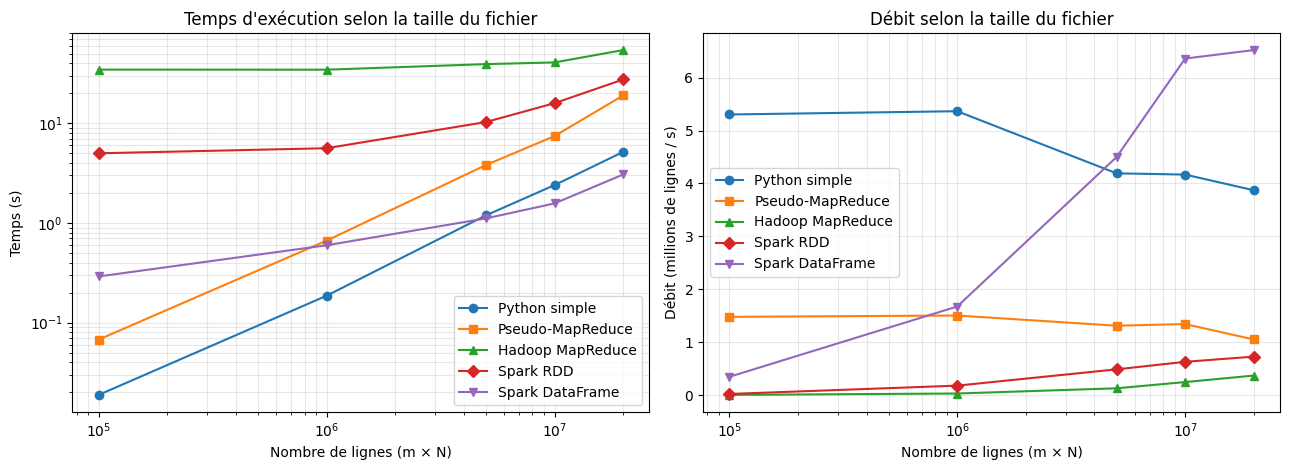

In [21]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
for c in cols:
    ax1.plot(resultats["lignes"], resultats[c], STYLES[c][0], label=STYLES[c][1])
    ax2.plot(resultats["lignes"], resultats["lignes"] / resultats[c] / 1e6, STYLES[c][0], label=STYLES[c][1])

ax1.set(xscale="log", yscale="log", xlabel="Nombre de lignes (m × N)", ylabel="Temps (s)",
        title="Temps d'exécution selon la taille du fichier")
ax2.set(xscale="log", xlabel="Nombre de lignes (m × N)", ylabel="Débit (millions de lignes / s)",
        title="Débit selon la taille du fichier")
for ax in (ax1, ax2):
    ax.grid(True, which="both", alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

### 7.4 Le parallélisme de Spark : nombre de partitions

Une tâche Spark traite une partition. Le nombre de partitions fixe donc le parallélisme possible.
Pour un fichier local, `textFile` demande ici au moins 2 partitions et découpe en morceaux d'au plus
32 Mo : le plus gros fichier (118 Mo) ne donne que 4 partitions, donc 4 tâches, alors que la machine a
plus de cœurs. On force un découpage plus fin avec le
second argument de `textFile` et on regarde l'effet sur la version RDD.

In [22]:
m_max = max(M_VALUES)
gros = FICHIERS[m_max]
attendu_gros = {mot: m_max * nb for mot, nb in reference_base.items()}

essais_partitions = []
for demande in [None, 12, 24]:
    t0 = time.perf_counter()
    res = compter_spark_rdd(sc, gros, demande)
    t = time.perf_counter() - t0
    assert res == attendu_gros
    obtenues = sc.textFile(gros.as_posix(), demande).getNumPartitions()
    essais_partitions.append({"partitions demandées": demande or "défaut", "partitions obtenues": obtenues,
                              "V4 Spark RDD (s)": round(t, 1)})
    print(f"{obtenues:>2} partitions : {t:5.1f} s  -> résultat identique")
pd.DataFrame(essais_partitions).set_index("partitions demandées")

 4 partitions :  24.4 s  -> résultat identique


12 partitions :  36.1 s  -> résultat identique


24 partitions :  59.9 s  -> résultat identique


,partitions obtenues,V4 Spark RDD (s)
partitions demandées,,
défaut,4,24.4
12,12,36.1
24,24,59.9


### 7.5 Le parallélisme de Spark : nombre de cœurs

On recrée la session avec `local[k]` pour limiter Spark à k fils d'exécution, toujours sur le plus gros
fichier (20 millions de lignes). La version RDD garde ses 4 partitions par défaut. Pour le DataFrame,
Spark choisit lui-même le découpage en fonction du nombre de cœurs. Le DataFrame est mesuré trois fois
(meilleur temps), le RDD une fois.

In [23]:
essais_coeurs = []
for k in sorted({1, 2, 4, os.cpu_count()}):
    spark.stop()
    spark = creer_session(f"local[{k}]")
    sc = spark.sparkContext
    compter_spark_df(spark, fichier_base)          # mise en route de la nouvelle session

    t_df, res = chronometrer(lambda f: compter_spark_df(spark, f), gros, 3)
    assert res == attendu_gros
    t_rdd, res = chronometrer(lambda f: compter_spark_rdd(sc, f), gros, 1)
    assert res == attendu_gros
    essais_coeurs.append({"cœurs (local[k])": k,
                          "partitions DataFrame": spark.read.text(gros.as_posix()).rdd.getNumPartitions(),
                          "V5 Spark DataFrame (s)": round(t_df, 2),
                          "partitions RDD": sc.textFile(gros.as_posix()).getNumPartitions(),
                          "V4 Spark RDD (s)": round(t_rdd, 1)})
    print(f"local[{k:>2}] : DataFrame {t_df:5.2f} s | RDD {t_rdd:5.1f} s  -> résultats identiques")

coeurs = pd.DataFrame(essais_coeurs).set_index("cœurs (local[k])")
coeurs["V1 Python simple (s)"] = round(resultats.loc[m_max, "V1 Python simple (s)"], 2)
coeurs

local[ 1] : DataFrame  9.95 s | RDD  49.4 s  -> résultats identiques


local[ 2] : DataFrame  5.86 s | RDD  31.6 s  -> résultats identiques


local[ 4] : DataFrame  4.52 s | RDD  25.5 s  -> résultats identiques


local[12] : DataFrame  2.82 s | RDD  24.2 s  -> résultats identiques


,partitions DataFrame,V5 Spark DataFrame (s),partitions RDD,V4 Spark RDD (s),V1 Python simple (s)
cœurs (local[k]),,,,,
1,1,9.95,4,49.4,5.17
2,2,5.86,4,31.6,5.17
4,4,4.52,4,25.5,5.17
12,12,2.82,4,24.2,5.17


## 8. Analyse et conclusion

*Les chiffres ci-dessous viennent de l'exécution de ce notebook (Windows 11, 12 cœurs logiques,
PySpark 3.5.9 en mode local, Java 8, Hadoop 3.4.1 sous Docker). Ils varient d'une exécution à l'autre,
parfois de 20 % ; les ordres de grandeur, eux, restent les mêmes.*

### 8.1 Justesse

Les cinq méthodes donnent **exactement les mêmes comptes** sur tous les fichiers, de 100 000 à
20 millions de lignes, et ces comptes valent bien m × ceux du fichier de base (vérifié par `assert`
à chaque taille). Les deux versions Spark passent les six cas de test (cas simple, fichier vide, lignes vides,
espaces, plusieurs mots par ligne, accents) et sont égales à `Counter` sur le fichier de base. Le
résultat ne dépend ni du nombre de partitions (4, 12, 24) ni du nombre de cœurs (1, 2, 4, 12).

La faute injectée (un `map` sans `split`) montre une limite des fichiers générés : comme ils ont un
seul mot par ligne, la version fausse y donne le bon résultat. Ce sont les cas « plusieurs » et
« espaces » qui la détectent. Sans eux, les tests n'auraient rien prouvé sur le découpage en mots.

### 8.2 Performances

Les temps Spark sont ceux du job, **session déjà démarrée**.

| Fichier | V1 Python simple | V2 pseudo-MapReduce | V3 Hadoop (job) | V4 Spark RDD | V5 Spark DataFrame | DataFrame / V1 |
|---|---|---|---|---|---|---|
| 100 000 lignes (0,6 Mo) | 0,019 s | 0,068 s | 34,6 s | 5,00 s | 0,29 s | × 15 |
| 1 M lignes (5,9 Mo) | 0,19 s | 0,67 s | 34,5 s | 5,63 s | 0,60 s | × 3,2 |
| 5 M lignes (29,5 Mo) | 1,19 s | 3,82 s | 39,3 s | 10,3 s | 1,11 s | × 0,93 |
| 10 M lignes (59 Mo) | 2,40 s | 7,45 s | 40,8 s | 15,9 s | 1,57 s | × 0,66 |
| 20 M lignes (118 Mo) | 5,17 s | 19,0 s | 54,3 s | 27,5 s | 3,07 s | × 0,59 |

1. **Spark a aussi un coût fixe, mais il ne le paie qu'une fois.** Démarrer la session prend 10,7 s,
   et le script complet sur 100 000 lignes 16,8 s (RDD) ou 19,0 s (DataFrame), démarrage de Python
   compris. Ensuite la JVM reste en vie : un job DataFrame minimal ne coûte plus que 0,17 s.
   Hadoop, lui, repaie environ 35 s **à chaque job** (34,6 s pour 100 000 lignes, 34,5 s pour un
   million), auxquelles s'ajoute la copie dans HDFS (6,6 à 22,5 s). Le premier job lancé juste après
   le démarrage du cluster a pris 54,5 s : il est écarté de la comparaison.

2. **Le DataFrame (V5) est la version Spark la plus rapide, et il dépasse Python simple à partir
   d'environ 5 millions de lignes.** À 20 millions de lignes, il met 3,07 s contre 5,17 s, soit 6,5 millions de
   lignes par seconde contre 3,9. À 5 millions de lignes, l'écart est faible (1,11 s contre 1,19 s, un
   seul essai) : le croisement se situe autour de cette taille. En dessous d'un million de lignes, Python simple reste devant
   (0,019 s contre 0,29 s) : le fichier est trop petit pour amortir la mise en place d'un job.

3. **Ce gain vient du parallélisme (partie 7.5).** Limité à un
   cœur, le job DataFrame met 9,95 s sur le plus gros fichier, presque deux fois plus que Python simple.
   Il passe à 5,86 s avec 2 cœurs, 4,52 s avec 4 et 2,82 s avec 12 : une accélération de 3,5 pour
   12 cœurs logiques, donc loin d'être proportionnelle.

4. **Le RDD (V4) donne les mêmes résultats, mais 9 à 17 fois plus lentement que le DataFrame**, et
   plus lentement que le pseudo-MapReduce du TP précédent à toutes les tailles. Les deux versions
   utilisent pourtant le même moteur. La différence est l'endroit où le calcul s'exécute : le
   DataFrame reste dans la JVM, alors que les fonctions `lambda` du RDD tournent dans des processus
   Python à qui la JVM doit envoyer les données. La partie 7.1 en donne un ordre de
   grandeur : un job RDD presque vide prend 1,19 s sur 1 partition et 13,0 s sur 12, soit environ une
   seconde de plus par tâche (ce temps couvre tout le job, pas seulement le lancement de Python). Sous Windows, PySpark ne garde pas de processus Python prêts d'une tâche à
   l'autre : chaque tâche en lance un nouveau. Les 5,0 s du comptage sur 100 000 lignes sont
   cohérentes avec cela (2 partitions, 2 étapes, donc 4 tâches).

5. **Plus de partitions n'accélère pas le RDD sur cette machine (partie 7.4).** Sur 20 millions de
   lignes, on passe de 24,4 s avec 4 partitions à 36,1 s avec 12, puis 59,9 s avec 24 : chaque
   partition ajoute des tâches, donc des processus Python à lancer. Côté cœurs, le RDD passe de
   49,4 s (1 cœur) à 25,5 s (4 cœurs), puis ne gagne presque plus rien (24,2 s avec 12) : avec
   4 partitions, il n'y a jamais plus de 4 tâches à la fois.

6. **Hadoop reste le plus lent ici**, de 10 fois (20 millions de lignes) à 1 800 fois (100 000 lignes)
   plus lent que Python simple, et 18 à 119 fois plus lent que le DataFrame. Son temps marginal est
   pourtant modéré : 19,7 s de plus entre 100 000 et 20 millions de lignes. C'est bien son coût fixe
   par job qui le pénalise.

Le calcul, lui, est le même partout. Le plan physique du DataFrame (partie 5) le montre :
`HashAggregate partial_count` (un comptage partiel par partition, le rôle du *combiner*), puis
`Exchange hashpartitioning` (le *shuffle*), puis `HashAggregate count` (le *reduce*).

### 8.3 Quand utiliser quoi ?

| Critère | Python simple | Hadoop MapReduce | Spark RDD (Python) | Spark DataFrame |
|---|---|---|---|---|
| Petit fichier (moins d'un million de lignes) | ✅ le plus rapide | ❌ ~35 s par job | ❌ ~5 s par job | ➖ 0,3 à 0,6 s par job, après ~11 s de démarrage |
| Fichier moyen, une machine (5 à 20 M lignes) | ✅ simple et correct | ❌ 10 à 33 fois plus lent que V1 | ❌ 5 à 9 fois plus lent que V1 | ✅ le plus rapide ici, grâce aux cœurs |
| Plusieurs calculs à la suite | ✅ | ❌ coût fixe à chaque job | ✅ la session reste ouverte | ✅ la session reste ouverte |
| Fichier plus gros que la RAM | ❌ tout est chargé en mémoire | ✅ bloc par bloc | ✅ partition par partition (non testé ici) | ✅ partition par partition (non testé ici) |
| Plusieurs machines | ❌ | ✅ | ✅ (non testé ici) | ✅ (non testé ici) |
| Simplicité de mise en place | ✅ 10 lignes | ❌ cluster HDFS + YARN | ✅ `pip install pyspark` + Java | ✅ `pip install pyspark` + Java |

### 8.4 Conclusion

Spark reprend le calcul de MapReduce (découper, regrouper par clé, agréger), mais il garde ses JVM
en vie d'un job à l'autre. Sur le même exemple et la même machine, le coût fixe d'un
job passe d'environ 35 s avec Hadoop à quelques dixièmes de seconde avec un DataFrame Spark, une fois
la session démarrée (10,7 s).

Le choix de l'API compte autant que le choix de Spark. Avec les mêmes données et le même moteur, le
RDD écrit en Python est 9 à 17 fois plus lent que le DataFrame, parce que chaque tâche passe par un
processus Python. Le DataFrame, exécuté dans la JVM et réparti sur les cœurs, est la seule des cinq
méthodes à battre la version Python simple, et seulement à partir d'environ 5 millions de lignes. Pour un
petit fichier, les dix lignes de Python du premier TP restent le meilleur choix.

Les cinq versions forment une progression : comprendre le calcul (V1), le reformuler en map / shuffle /
reduce (V2), le distribuer avec Hadoop (V3), l'écrire avec les mêmes opérations dans Spark (V4), puis
laisser Spark l'optimiser et l'exécuter lui-même (V5).

**Limites de l'expérience :**

- Une seule machine, Spark en mode local : ni HDFS, ni YARN, ni réseau. On mesure le parallélisme sur
  les cœurs, pas le comportement sur un cluster.
- La comparaison avec Hadoop n'est pas à armes égales : Hadoop tourne dans des conteneurs Docker et
  lit dans HDFS, Spark tourne directement sous Windows et lit le fichier local.
- Windows pénalise la version RDD (un processus Python par tâche). On ne l'a pas mesurée sous Linux.
- Des fichiers d'au plus 118 Mo et un vocabulaire de 15 mots : le shuffle ne transporte presque rien.
- Un seul essai au-delà d'un million de lignes, sur une machine qui faisait autre chose en même temps.

### Nettoyage

On arrête la session Spark. Pour arrêter aussi le cluster Hadoop et supprimer ses conteneurs, passer
`ARRETER` à `True`. Les fichiers générés sont dans `data/` (environ 200 Mo) : on peut les effacer à la main.

In [24]:
spark.stop()

ARRETER = False
if DOCKER_OK and ARRETER:
    print(sh(f"{COMPOSE} down").stderr)